In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

In [12]:
data = load_breast_cancer()

X = data.data
y = data.target

In [13]:
# Select three features: mean radius, mean texture, and mean perimeter
feature_indices = [0, 1, 2]
X = data.data[:, feature_indices]

print("Features:", data.feature_names[feature_indices])
print("X shape:", X.shape)

Features: ['mean radius' 'mean texture' 'mean perimeter']
X shape: (569, 3)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=101,
    stratify=y
)

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
model = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    max_iter=5000
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=5000)

In [17]:
theta_0 = model.intercept_[0]
theta_1, theta_2, theta_3 = model.coef_[0]

print("theta_0 =", theta_0)
print("theta_1 =", theta_1)
print("theta_2 =", theta_2)
print("theta_3 =", theta_3)

theta_0 = 18.79691005877087
theta_1 = 2.9489201300939225
theta_2 = -0.23275592403659956
theta_3 = -0.6006252267032655


In [18]:
x1_values = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
x2_values = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
X1, X2 = np.meshgrid(x1_values, x2_values)
X3 = -(theta_0 + theta_1 * X1 + theta_2 * X2) / theta_3

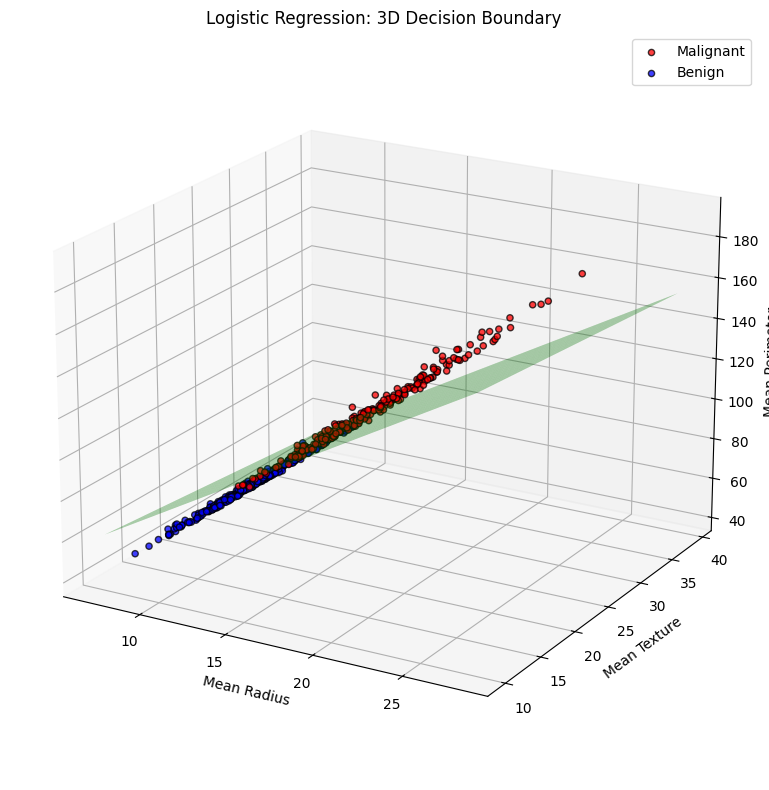

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # Enables 3D plotting

# --- ASSUMED SETUP (Ensure your model variables match this) ---
# model = your trained LogisticRegression model
# X = your 3D training array (columns: Radius, Texture, Perimeter)
# y = your binary target array (0: Malignant, 1: Benign)

# 1. Extract weights and intercept from your trained logistic regression model
w0, w1, w2 = model.coef_[0]
b = model.intercept_[0]

# 2. Generate a 2D mesh grid for X1 (Radius) and X2 (Texture) using np.linspace
x1_range = np.linspace(X[:, 0].min(), X[:, 0].max(), 30)
x2_range = np.linspace(X[:, 1].min(), X[:, 1].max(), 30)
X1, X2 = np.meshgrid(x1_range, x2_range)  # Converts 1D arrays to 2D matrices

# 3. Calculate the corresponding 2D matrix for X3 (Perimeter) using the decision boundary equation
X3 = -(w0 * X1 + w1 * X2 + b) / w2

# --- YOUR FIXES APPLIED BELOW ---
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot malignant and benign samples (Ensure y indexing matches your data shape)
ax.scatter(
    X[y == 0, 0], X[y == 0, 1], X[y == 0, 2],
    label='Malignant', alpha=0.75, color='red', edgecolors='k'
)
ax.scatter(
    X[y == 1, 0], X[y == 1, 1], X[y == 1, 2],
    label='Benign', alpha=0.75, color='blue', edgecolors='k'
)

# Plot the 3D decision-boundary plane (Now passes matching 2D matrices)
ax.plot_surface(X1, X2, X3, alpha=0.35, color='green')

ax.set_xlabel('Mean Radius')
ax.set_ylabel('Mean Texture')
ax.set_zlabel('Mean Perimeter')
ax.set_title('Logistic Regression: 3D Decision Boundary')
ax.legend()
ax.view_init(elev=20, azim=-60)
plt.tight_layout()
plt.show()


coef shape: (1, 3)
weights match model.decision_function(X): True
decision values range: -18.715052969335552 9.956030749809017
Solving for axis: Mean Radius
Plane visible fraction: 70.24%


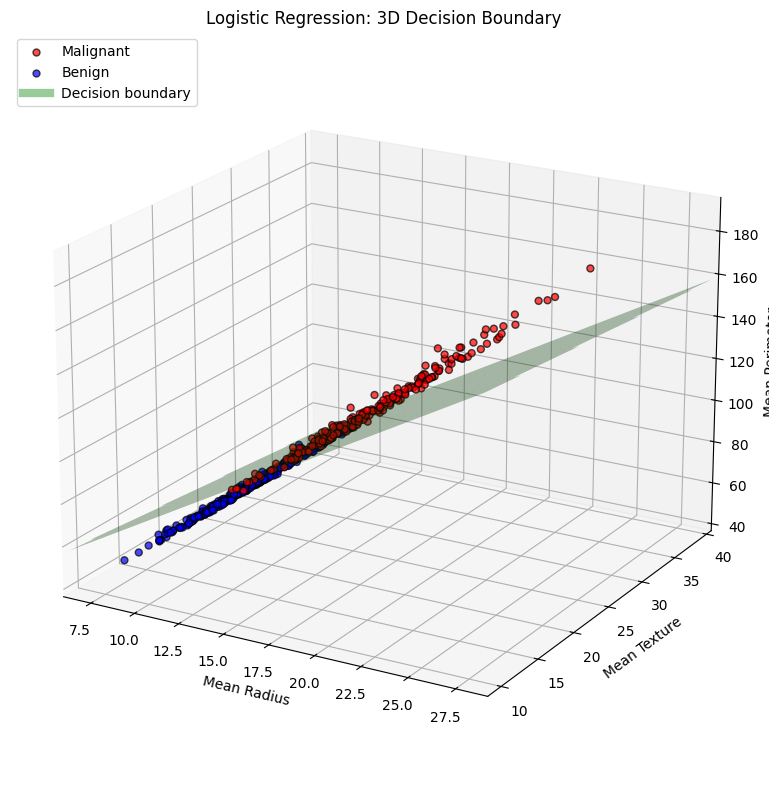

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

# ASSUMED: model (LogisticRegression fit on exactly these 3 columns of X), X (n,3), y (0/1)
w = model.coef_[0].astype(float)
b = float(model.intercept_[0])

# --- Sanity check: do the weights actually reproduce the model on THIS X? ---
manual = X @ w + b
print("coef shape:", model.coef_.shape)
print("weights match model.decision_function(X):",
      np.allclose(manual, model.decision_function(X), atol=1e-6))
print("decision values range:", manual.min(), manual.max())

names = ['Mean Radius', 'Mean Texture', 'Mean Perimeter']
lo = X.min(axis=0); hi = X.max(axis=0)
pad = (hi - lo) * 0.05
lo, hi = lo - pad, hi + pad

# Solve for the axis with the largest |weight| -> most stable plane
k = int(np.argmax(np.abs(w)))
i, j = [a for a in range(3) if a != k]
print("Solving for axis:", names[k])

G1, G2 = np.meshgrid(np.linspace(lo[i], hi[i], 50),
                     np.linspace(lo[j], hi[j], 50))
Gk = -(w[i] * G1 + w[j] * G2 + b) / w[k]

# Place grids back into (x, y, z) order
grids = [None, None, None]
grids[i], grids[j], grids[k] = G1, G2, Gk
PX, PY, PZ = grids

# Mask only values outside the padded range of the solved axis
inside = (Gk >= lo[k]) & (Gk <= hi[k])
print(f"Plane visible fraction: {inside.mean():.2%}")
Gk_masked = np.where(inside, Gk, np.nan)
grids[k] = Gk_masked
PX, PY, PZ = grids

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[y == 0, 0], X[y == 0, 1], X[y == 0, 2],
           label='Malignant', color='red', alpha=0.7, edgecolors='k', s=25)
ax.scatter(X[y == 1, 0], X[y == 1, 1], X[y == 1, 2],
           label='Benign', color='blue', alpha=0.7, edgecolors='k', s=25)

if inside.any():
    ax.plot_surface(PX, PY, PZ, alpha=0.35, color='green', linewidth=0)
else:
    print("Plane lies completely outside the data range -> weights don't match X "
          "(check scaling / feature order / number of features).")

ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
ax.set_xlabel(names[0]); ax.set_ylabel(names[1]); ax.set_zlabel(names[2])
ax.set_title('Logistic Regression: 3D Decision Boundary')
ax.view_init(elev=20, azim=-60)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='green', lw=6, alpha=0.4))
labels.append('Decision boundary')
ax.legend(handles, labels, loc='upper left')
plt.tight_layout()
plt.show()